In [2]:
%pip install --quiet ultralytics roboflow google-cloud-aiplatform opencv-python-headless

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import IPython

app = IPython.Application.instance()
app.kernel.do_shutdown(True)

In [ ]:
import os
import cv2
from roboflow import Roboflow
from ultralytics import YOLO
import vertexai
from vertexai.generative_models import GenerativeModel, Part, Image  # Imported 'Image' to fix the local image loading bug

# ==========================================
# 1. Environment Setup & API Configurations
# ==========================================
ROBOFLOW_API_KEY = "PIlWf3SW88eM18FTSeCr"
GCP_PROJECT_ID = "duyuthon"

# Initialize Vertex AI (For Gemini Model)
vertexai.init(project=GCP_PROJECT_ID, location="us-central1")
gemini_model = GenerativeModel("gemini-2.5-flash")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

# ==========================================
# 2. Model Training (Utilizing T4 GPU) 
# Run this once, then comment it out after training is complete!
# ==========================================
def train_models():
    print("--- Starting Student Detection Model Training ---")
    student_dataset = rf.workspace("amine-dnsi2").project("classroom-sjp9h").version(1).download("yolov8")
    model_student = YOLO("yolov8n.pt")
    # Maximize T4 usage for fast training (epochs set to 30 to optimize time/cost)
    model_student.train(data=f"{student_dataset.location}/data.yaml", epochs=30, imgsz=640, project="campus", name="student_model", device="cpu")

    print("--- Starting Air Conditioner Detection Model Training ---")
    ac_dataset = rf.workspace("detection-3h20r").project("4-way-air-conditioner").version(1).download("yolov8")
    model_ac = YOLO("yolov8n.pt")
    model_ac.train(data=f"{ac_dataset.location}/data.yaml", epochs=30, imgsz=640, project="campus", name="ac_model", device="cpu")
    
    print("Training Complete! 'campus/student_model/weights/best.pt' and 'campus/ac_model/weights/best.pt' have been successfully generated.")

# ==========================================
# 3. Inference Logic (Student Presence + AC State Determination)
# ==========================================
def check_ac_status_with_gemini(crop_img_path):
    """Sends the cropped air conditioner image to Gemini to check its operational state."""
    # Fixed the double Part.from_image bug using Vertex AI's native Image loader
    image_part = Part.from_image(Image.load_from_file(crop_img_path)) 
    prompt = """
    This image shows a ceiling-mounted 4-way classroom air conditioner. 
    1. If the air-directing louvers (vanes) are visibly open or the operation LED is turned on, return 'ON'.
    2. If the louvers are completely shut and the unit is powered down, return 'OFF'.
    The output format must strictly be a raw JSON object matching this structure: {"status": "ON", "reason": "detailed explanation"}
    Do not wrap the response in markdown block formatting code tags.
    """
    response = gemini_model.generate_content([image_part, prompt])
    return response.text

def analyze_classroom_image(image_path, student_model_path, ac_model_path):
    print(f"\n--- [Analysis Started] {image_path} ---")
    
    # Load models (Lightweight Nano models are fast on both CPU and GPU)
    student_model = YOLO(student_model_path)
    ac_model = YOLO(ac_model_path)
    
    # Step 1: Check Student Presence
    student_results = student_model(image_path)[0]
    student_count = len(student_results.boxes)
    print(f"Detected Students: {student_count}")
    
    if student_count > 0:
        return {"result": "PASS", "message": "Students are present in the classroom. Keeping the AC on is justified."}
    
    print("The classroom is empty. Initiating air conditioner detection sequence...")
    
    # Step 2: Detect Air Conditioner Units
    ac_results = ac_model(image_path)[0]
    if len(ac_results.boxes) == 0:
        return {"result": "PASS", "message": "No air conditioning units detected in the frame."}
    
    # Step 3: If AC units are found, crop out the bounding boxes and evaluate via Gemini
    img = cv2.imread(image_path)
    for i, box in enumerate(ac_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        ac_crop = img[y1:y2, x1:x2]
        
        # Save as a temporary image file
        temp_crop_path = f"temp_ac_crop_{i}.jpg"
        cv2.imwrite(temp_crop_path, ac_crop)
        
        # Consult Gemini on whether the AC unit is running
        print("Air conditioner detected! Evaluating ON/OFF status with Gemini AI...")
        ac_status = check_ac_status_with_gemini(temp_crop_path)
        print(f"Gemini Analysis Output: {ac_status}")
        
        # Clean up the temporary cropped image file
        os.remove(temp_crop_path)
        
        # Standardized token match check for automated detection
        if "ON" in ac_status.upper():
            return {
                "result": "WASTE_DETECTED", 
                "message": "Energy waste detected! The air conditioner is left ON in an empty classroom. (System action / point deduction required)", 
                "details": ac_status
            }

    return {"result": "PASS", "message": "The classroom is empty, and the air conditioner is turned OFF."}

# ==========================================
# Main Execution Block
# ==========================================
if __name__ == "__main__":
    train_models() 
    
    test_image = "test_classroom.jpg" 
    result = analyze_classroom_image(
         test_image, 
         student_model_path="campus/student_model/weights/best.pt",
         ac_model_path="campus/ac_model/weights/best.pt"
    )
    print(result)

--- Starting Student Detection Model Training ---
loading Roboflow workspace...
loading Roboflow project...
Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.12.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jupyter/classroom-1/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_sc

In [ ]:
print("Job Finished")

In [9]:
def check_status_with_gemini(original_img_path, crop_img_path):
    """
    Sends the original image (for lighting context) and cropped image (for AC details)
    to Gemini to determine the power status.
    """
    original_part = Part.from_image(Part.from_image(original_img_path))
    crop_part = Part.from_image(Part.from_image(crop_img_path))
    
    # English prompt is highly recommended for better accuracy and strict JSON parsing
    prompt = """
    You are a building energy management AI.
    The first image is the original full photo of a classroom. 
    The second image is a cropped close-up of a ceiling 4-way air conditioner.
    Analyze the following two power states:

    1. "ac_status": Look at the second image (AC). If the louvers (blades) are open or the operation LED is on, return "ON". If they are closed and inactive, return "OFF".
    2. "light_status": Look at the background of the first image (original). If the ceiling indoor lights (fluorescent/LED) are turned on and emitting light, return "ON". If they are turned off, return "OFF" (Do not confuse natural sunlight from windows with artificial lighting).

    Respond STRICTLY in the following JSON format only. Do not include any markdown formatting like ```json.
    {
        "ac_status": "ON or OFF",
        "light_status": "ON or OFF",
        "reason": "Your detailed reasoning for this judgment"
    }
    """
    
    response = gemini_model.generate_content([original_part, crop_part, prompt])
    return response.text

def analyze_classroom_image(image_path, student_model_path, ac_model_path):
    print(f"\n--- [Analysis Started] {image_path} ---")
    
    # Load Models
    student_model = YOLO(student_model_path)
    ac_model = YOLO(ac_model_path)
    
    # Step 1: Check for students
    student_results = student_model(image_path)[0]
    student_count = len(student_results.boxes)
    print(f"Detected students: {student_count}")
    
    if student_count > 0:
        return {"result": "PASS", "message": "Students are present in the classroom. Status normal."}
    
    print("Classroom is empty. Checking for energy waste (AC and Lights)...")
    
    # Step 2: Detect Air Conditioner
    ac_results = ac_model(image_path)[0]
    if len(ac_results.boxes) == 0:
        return {"result": "ERROR", "message": "Air conditioner not found in the image."}
    
    # Step 3: Crop AC and request Gemini Analysis
    img = cv2.imread(image_path)
    for i, box in enumerate(ac_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        ac_crop = img[y1:y2, x1:x2]
        
        temp_crop_path = f"temp_ac_crop_{i}.jpg"
        cv2.imwrite(temp_crop_path, ac_crop)
        
        print("Analyzing AC and background lighting status using Gemini AI...")
        ai_response = check_status_with_gemini(image_path, temp_crop_path)
        
        # Clean up temporary crop file
        os.remove(temp_crop_path)
        
        try:
            # Safely parse JSON response from Gemini
            # Stripping markdown just in case Gemini includes it despite the prompt
            clean_json_str = ai_response.strip().strip("```json").strip("```").strip()
            status_data = json.loads(clean_json_str)
            
            ac_on = (status_data.get("ac_status") == "ON")
            light_on = (status_data.get("light_status") == "ON")
            
            if ac_on or light_on:
                return {
                    "result": "WASTE_DETECTED",
                    "message": "Energy waste detected in an empty classroom!",
                    "ac_status": status_data.get("ac_status"),
                    "light_status": status_data.get("light_status"),
                    "reason": status_data.get("reason")
                }
            else:
                return {"result": "PASS", "message": "Classroom is empty and all power sources are OFF."}
                
        except json.JSONDecodeError:
            return {"result": "ERROR", "message": f"Failed to parse Gemini response: {ai_response}"}

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    test_image = "test_classroom.jpg" 
    result = analyze_classroom_image(
     test_image, 
         student_model_path="runs/detect/campus/student_model/weights/best.pt",
         ac_model_path="runs/detect/campus/ac_model/weights/best.pt"
    )
    print(result)


--- [Analysis Started] test_classroom.jpg ---

image 1/1 /home/jupyter/test_classroom.jpg: 640x480 1 with-student, 6 without-students, 100.7ms
Speed: 3.7ms preprocess, 100.7ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 480)
Detected students: 7
{'result': 'PASS', 'message': 'Students are present in the classroom. Status normal.'}


In [13]:
def analyze_ac_only(image_path, student_model_path, ac_model_path):
    print(f"\n--- [Analysis Started] {image_path} ---")
    
    # Load Models
    student_model = YOLO(student_model_path)
    ac_model = YOLO(ac_model_path)
    """
    # Step 1: Check for students
    student_results = student_model(image_path)[0]
    student_count = len(student_results.boxes)
    print(f"Detected students: {student_count}")
    
    if student_count > 0:
        return {"result": "PASS", "message": "Students are present in the classroom. Status normal."}
    
    print("Classroom is empty. Checking for energy waste (AC and Lights)...")
    """
    # Step 2: Detect Air Conditioner
    ac_results = ac_model(image_path)[0]
    if len(ac_results.boxes) == 0:
        return {"result": "ERROR", "message": "Air conditioner not found in the image."}
    
    # Step 3: Crop AC and request Gemini Analysis
    img = cv2.imread(image_path)
    for i, box in enumerate(ac_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        ac_crop = img[x1:x2, y1:y2]
        
        temp_crop_path = f"temp_ac_crop_{i}.jpg"
        cv2.imwrite(temp_crop_path, ac_crop)
        
        print("Analyzing AC and background lighting status using Gemini AI...")
        ai_response = check_status_with_gemini(image_path, temp_crop_path)
        
        # Clean up temporary crop file
        os.remove(temp_crop_path)
        
        try:
            # Safely parse JSON response from Gemini
            # Stripping markdown just in case Gemini includes it despite the prompt
            clean_json_str = ai_response.strip().strip("```json").strip("```").strip()
            status_data = json.loads(clean_json_str)
            
            ac_on = (status_data.get("ac_status") == "ON")
            light_on = (status_data.get("light_status") == "ON")
            
            if ac_on or light_on:
                return {
                    "result": "WASTE_DETECTED",
                    "message": "Energy waste detected in an empty classroom!",
                    "ac_status": status_data.get("ac_status"),
                    "light_status": status_data.get("light_status"),
                    "reason": status_data.get("reason")
                }
            else:
                return {"result": "PASS", "message": "Classroom is empty and all power sources are OFF."}
                
        except json.JSONDecodeError:
            return {"result": "ERROR", "message": f"Failed to parse Gemini response: {ai_response}"}

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    test_image = "test_classroom.jpg" 
    result = analyze_ac_only(
     test_image, 
         student_model_path="runs/detect/campus/student_model/weights/best.pt",
         ac_model_path="runs/detect/campus/ac_model/weights/best.pt"
    )
    print(result)


--- [Analysis Started] test_classroom.jpg ---

image 1/1 /home/jupyter/test_classroom.jpg: 640x480 (no detections), 112.6ms
Speed: 3.7ms preprocess, 112.6ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 480)
{'result': 'ERROR', 'message': 'Air conditioner not found in the image.'}


In [14]:
if __name__ == "__main__":
    test_image = "test_again.png" 
    result = analyze_ac_only(
     test_image, 
         student_model_path="runs/detect/campus/student_model/weights/best.pt",
         ac_model_path="runs/detect/campus/ac_model/weights/best.pt"
    )
    print(result)


--- [Analysis Started] test_again.png ---

image 1/1 /home/jupyter/test_again.png: 480x640 1 94, 111.1ms
Speed: 2.7ms preprocess, 111.1ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)
Analyzing AC and background lighting status using Gemini AI...


AttributeError: 'str' object has no attribute 'data'


--- [Analysis Started] test_again.png ---



This feature is deprecated as of June 24, 2025 and will be removed on June 24, 2026. For details, see https://cloud.google.com/vertex-ai/generative-ai/docs/deprecations/genai-vertexai-sdk.


image 1/1 /home/jupyter/test_again.png: 480x640 1 94, 152.2ms
Speed: 3.4ms preprocess, 152.2ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)


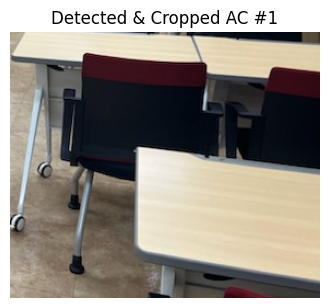

Analyzing AC and background lighting status using Gemini AI...


NotFound: 404 Publisher Model `projects/duyuthon/locations/us-west4/publishers/google/models/gemini-1.5-flash-001` was not found or your project does not have access to it. Please ensure you are using a valid model version. For more information, see: https://cloud.google.com/vertex-ai/generative-ai/docs/learn/model-versions

In [15]:
import os
import cv2
import json
import vertexai
import matplotlib.pyplot as plt  # 이미지를 화면에 보여주기 위해 추가
from vertexai.generative_models import GenerativeModel, Part, Image  # Image 모듈 추가
from ultralytics import YOLO

# ==========================================
# 1. Configuration & Initialization
# ==========================================

vertexai.init(project=GCP_PROJECT_ID, location="us-west4")
gemini_model = GenerativeModel("gemini-1.5-flash-001")

# ==========================================
# 2. Gemini Analysis Function
# ==========================================
def check_status_with_gemini(original_img_path, crop_img_path):
    """
    Sends the original image (for lighting context) and cropped image (for AC details)
    to Gemini to determine the power status.
    """
    # [수정됨] 에러 해결: Image.load_from_file()을 사용하여 로컬 이미지를 안전하게 로드합니다.
    original_img = Image.load_from_file(original_img_path)
    crop_img = Image.load_from_file(crop_img_path)
    
    original_part = Part.from_image(original_img)
    crop_part = Part.from_image(crop_img)
    
    prompt = """
    You are a building energy management AI.
    The first image is the original full photo of a classroom. 
    The second image is a cropped close-up of a ceiling 4-way air conditioner.
    Analyze the following two power states:

    1. "ac_status": Look at the second image (AC). If the louvers (blades) are open or the operation LED is on, return "ON". If they are closed and inactive, return "OFF".
    2. "light_status": Look at the background of the first image (original). If the ceiling indoor lights (fluorescent/LED) are turned on and emitting light, return "ON". If they are turned off, return "OFF" (Do not confuse natural sunlight from windows with artificial lighting).

    Respond STRICTLY in the following JSON format only. Do not include any markdown formatting like ```json.
    {
        "ac_status": "ON or OFF",
        "light_status": "ON or OFF",
        "reason": "Your detailed reasoning for this judgment"
    }
    """
    
    response = gemini_model.generate_content([original_part, crop_part, prompt])
    return response.text


# ==========================================
# 3. Detection & Cropping Function
# ==========================================
def analyze_ac_only(image_path, student_model_path, ac_model_path):
    print(f"\n--- [Analysis Started] {image_path} ---")
    
    # Load Models
    student_model = YOLO(student_model_path)
    ac_model = YOLO(ac_model_path)
    
    """
    # Step 1: Check for students (주석 처리됨)
    student_results = student_model(image_path)[0]
    student_count = len(student_results.boxes)
    print(f"Detected students: {student_count}")
    
    if student_count > 0:
        return {"result": "PASS", "message": "Students are present in the classroom. Status normal."}
    
    print("Classroom is empty. Checking for energy waste (AC and Lights)...")
    """
    
    # Step 2: Detect Air Conditioner
    ac_results = ac_model(image_path)[0]
    if len(ac_results.boxes) == 0:
        return {"result": "ERROR", "message": "Air conditioner not found in the image."}
    
    # Step 3: Crop AC and request Gemini Analysis
    img = cv2.imread(image_path)
    for i, box in enumerate(ac_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        
        # [수정됨] OpenCV 배열 슬라이싱 순서는 [y(높이), x(너비)] 입니다.
        ac_crop = img[y1:y2, x1:x2] 
        
        # --- [추가됨] 크롭된 이미지를 주피터 노트북 화면에 출력하여 확인 ---
        # OpenCV는 BGR을 사용하고 Matplotlib은 RGB를 사용하므로 색상 변환이 필요합니다.
        ac_crop_rgb = cv2.cvtColor(ac_crop, cv2.COLOR_BGR2RGB)
        
        plt.figure(figsize=(4, 4))
        plt.imshow(ac_crop_rgb)
        plt.title(f"Detected & Cropped AC #{i+1}")
        plt.axis('off')
        plt.show()  # 여기서 크롭된 이미지가 출력됩니다!
        # -----------------------------------------------------------
        
        temp_crop_path = f"temp_ac_crop_{i}.jpg"
        cv2.imwrite(temp_crop_path, ac_crop)
        
        print("Analyzing AC and background lighting status using Gemini AI...")
        ai_response = check_status_with_gemini(image_path, temp_crop_path)
        
        # Clean up temporary crop file
        os.remove(temp_crop_path)
        
        try:
            # Safely parse JSON response from Gemini
            clean_json_str = ai_response.strip().strip("```json").strip("```").strip()
            status_data = json.loads(clean_json_str)
            
            ac_on = (status_data.get("ac_status") == "ON")
            light_on = (status_data.get("light_status") == "ON")
            
            if ac_on or light_on:
                return {
                    "result": "WASTE_DETECTED",
                    "message": "Energy waste detected in an empty classroom!",
                    "ac_status": status_data.get("ac_status"),
                    "light_status": status_data.get("light_status"),
                    "reason": status_data.get("reason")
                }
            else:
                return {"result": "PASS", "message": "Classroom is empty and all power sources are OFF."}
                
        except json.JSONDecodeError:
            return {"result": "ERROR", "message": f"Failed to parse Gemini response: {ai_response}"}

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    test_image = "test_again.png" 
    result = analyze_ac_only(
         image_path=test_image, 
         student_model_path="runs/detect/campus/student_model/weights/best.pt",
         ac_model_path="runs/detect/campus/ac_model/weights/best.pt"
    )
    print(json.dumps(result, indent=4, ensure_ascii=False))


--- [Analysis Started] why.jpeg ---

image 1/1 /home/jupyter/why.jpeg: 480x640 2 94s, 104.2ms
Speed: 3.1ms preprocess, 104.2ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)


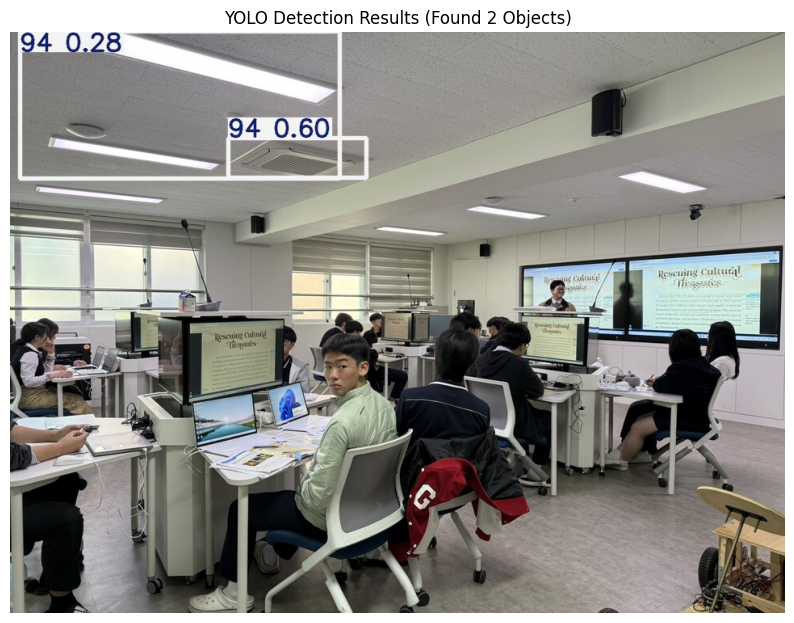

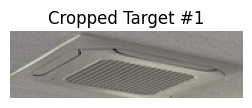

Sending Target #1 to Gemini AI...


NotFound: 404 Publisher Model `projects/duyuthon/locations/us-central1/publishers/google/models/gemini-1.5-flash` was not found or your project does not have access to it. Please ensure you are using a valid model version. For more information, see: https://cloud.google.com/vertex-ai/generative-ai/docs/learn/model-versions

In [18]:
import os
import cv2
import json
import vertexai
import matplotlib.pyplot as plt
from vertexai.generative_models import GenerativeModel, Part, Image
from ultralytics import YOLO

# ==========================================
# 1. Configuration & Initialization
# ==========================================
# 에러 로그에 나온 프로젝트 ID 'duyuthon'을 적용했습니다.
GCP_PROJECT_ID = "duyuthon"  

# 강제로 us-central1 리전을 사용하도록 설정
vertexai.init(project=GCP_PROJECT_ID, location="us-central1")

# 모델 이름을 특정 버전(001)이 아닌 기본 flash로 변경하여 404 에러 방지
gemini_model = GenerativeModel("gemini-1.5-flash") 

# ==========================================
# 2. Gemini Analysis Function
# ==========================================
def check_status_with_gemini(original_img_path, crop_img_path):
    original_img = Image.load_from_file(original_img_path)
    crop_img = Image.load_from_file(crop_img_path)
    
    original_part = Part.from_image(original_img)
    crop_part = Part.from_image(crop_img)
    
    prompt = """
    You are a building energy management AI.
    The first image is the original full photo of a classroom. 
    The second image is a cropped close-up of a ceiling 4-way air conditioner.
    Analyze the following two power states:

    1. "ac_status": Look at the second image (AC). If the louvers (blades) are open or the operation LED is on, return "ON". If they are closed and inactive, return "OFF".
    2. "light_status": Look at the background of the first image (original). If the ceiling indoor lights (fluorescent/LED) are turned on and emitting light, return "ON". If they are turned off, return "OFF".

    Respond STRICTLY in the following JSON format only:
    {
        "ac_status": "ON or OFF",
        "light_status": "ON or OFF",
        "reason": "Your detailed reasoning"
    }
    """
    response = gemini_model.generate_content([original_part, crop_part, prompt])
    return response.text

# ==========================================
# 3. Detection & Debugging Function
# ==========================================
def analyze_ac_only(image_path, student_model_path, ac_model_path):
    print(f"\n--- [Analysis Started] {image_path} ---")
    
    ac_model = YOLO(ac_model_path)
    
    # [수정 핵심 1] conf=0.5를 주어 50% 이상 확실한 것만 에어컨으로 잡도록 필터링!
    ac_results = ac_model(image_path)[0]
    
    # ---------------------------------------------------------
    # [수정 핵심 2] YOLO가 인식한 전체 바운딩 박스 결과 화면에 출력 (디버깅용)
    # ---------------------------------------------------------
    annotated_img = ac_results.plot() # YOLO가 네모 박스와 확률을 그려준 이미지 생성
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_img_rgb)
    plt.title(f"YOLO Detection Results (Found {len(ac_results.boxes)} Objects)")
    plt.axis('off')
    plt.show() 
    # ---------------------------------------------------------
    
    if len(ac_results.boxes) == 0:
        return {"result": "ERROR", "message": "Air conditioner not found in the image. (Confidence was too low)"}
    
    img = cv2.imread(image_path)
    for i, box in enumerate(ac_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        ac_crop = img[y1:y2, x1:x2] 
        
        # 크롭된 이미지도 확인
        ac_crop_rgb = cv2.cvtColor(ac_crop, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(3, 3))
        plt.imshow(ac_crop_rgb)
        plt.title(f"Cropped Target #{i+1}")
        plt.axis('off')
        plt.show()
        
        temp_crop_path = f"temp_ac_crop_{i}.jpg"
        cv2.imwrite(temp_crop_path, ac_crop)
        
        print(f"Sending Target #{i+1} to Gemini AI...")
        
        # [수정 핵심 3] 여기서 Gemini 404 에러가 나지 않도록 위에서 초기화 설정을 바꿨습니다.
        ai_response = check_status_with_gemini(image_path, temp_crop_path)
        os.remove(temp_crop_path)
        
        try:
            clean_json_str = ai_response.strip().strip("```json").strip("```").strip()
            status_data = json.loads(clean_json_str)
            
            ac_on = (status_data.get("ac_status") == "ON")
            light_on = (status_data.get("light_status") == "ON")
            
            if ac_on or light_on:
                return {
                    "result": "WASTE_DETECTED",
                    "message": "Energy waste detected!",
                    "ac_status": status_data.get("ac_status"),
                    "light_status": status_data.get("light_status"),
                    "reason": status_data.get("reason")
                }
            else:
                return {"result": "PASS", "message": "All power sources are OFF."}
                
        except json.JSONDecodeError:
            return {"result": "ERROR", "message": f"Parse Error: {ai_response}"}

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    test_image = "why.jpeg" 
    result = analyze_ac_only(
         image_path=test_image, 
         student_model_path="runs/detect/campus/student_model/weights/best.pt",
         ac_model_path="runs/detect/campus/ac_model/weights/best.pt"
    )
    print(json.dumps(result, indent=4, ensure_ascii=False))

In [19]:
gemini_model = GenerativeModel("gemini-2.5-flash")


--- [Analysis Started] why.jpeg ---

image 1/1 /home/jupyter/why.jpeg: 480x640 2 94s, 106.5ms
Speed: 2.9ms preprocess, 106.5ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)


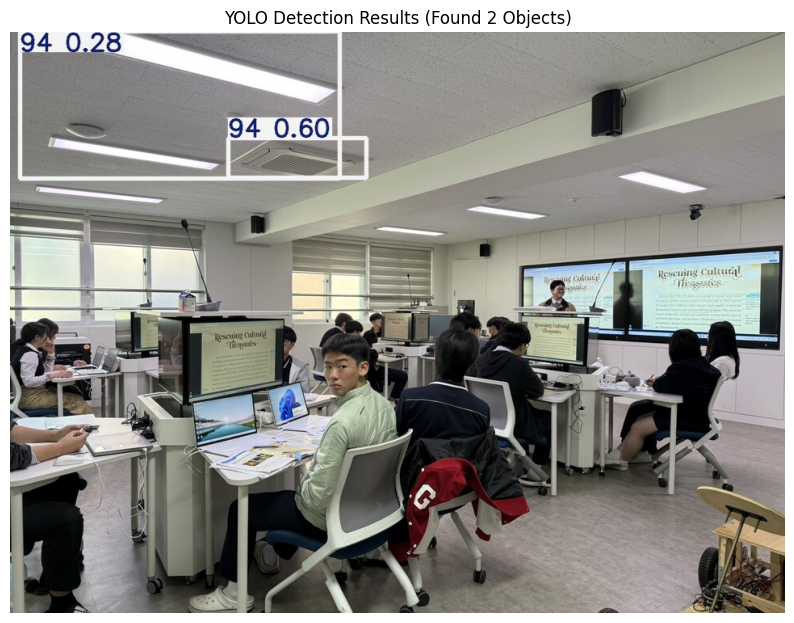

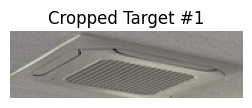

Sending Target #1 to Gemini AI...
{
    "result": "WASTE_DETECTED",
    "message": "Energy waste detected!",
    "ac_status": "OFF",
    "light_status": "ON",
    "reason": "For 'ac_status', the close-up image of the ceiling AC unit shows its louvers (blades) are closed and flush with the unit, indicating it is not actively operating. There are no visible indicator lights that suggest it is on. For 'light_status', the first image of the classroom clearly shows multiple rectangular ceiling light fixtures are illuminated and emitting light, brightening the room."
}


In [20]:
if __name__ == "__main__":
    test_image = "why.jpeg" 
    result = analyze_ac_only(
         image_path=test_image, 
         student_model_path="runs/detect/campus/student_model/weights/best.pt",
         ac_model_path="runs/detect/campus/ac_model/weights/best.pt"
    )
    print(json.dumps(result, indent=4, ensure_ascii=False))